<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/05-%20Valutazione_sul_Test_Set_e_Interpretabilit%C3%A0_(SHAP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Protocollo di Valutazione e Trasparenza Metodologica:**
Per preservare l'affidabilità della stima finale, la scelta del modello (Regressione Logistica), il set di feature e la procedura di tuning sono definiti indipendentemente dalle prestazioni sul Test Set. Quest'ultimo svolge esclusivamente il ruolo di verifica finale su dati mai visti (*unseen*) e non viene mai utilizzato come feedback per ottimizzare o selezionare il modello.
è importante dire che successivamente a una prima esecuzione sul Test Set sono state applicate tre rifiniture di natura strettamente metodologica e interpretativa (non guidate dalle metriche di test):
1. l'incapsulamento dello `StandardScaler` all'interno della `Pipeline` anche in fase di Cross-Validation;
2. l'infittimento della griglia di `C` con l'estensione alla penalità L1;
3. la riparametrizzazione lineare di `white_rating` e `black_rating` in `rating_diff` e `rating_mean` per rimuovere la collinearità perfetta prima dell'analisi SHAP.

# 5. Modello Finale, Valutazione sul Test Set e Interpretabilità

In questo capitolo finale, l'analisi si sposta dalla validazione incrociata (Train) alla valutazione definitiva sul Test Set, al fine di dimostrare l'evoluzione temporale del potere predittivo al variare di $N$.

**Dichiarazione Metodologica Pre-Test:**
Per garantire l'assoluta validità scientifica dell'esperimento, lo spazio di ricerca degli iperparametri e la pipeline di pre-elaborazione sono stati rigorosamente fissati *prima* di esporre il modello al Test Set. Qualsiasi metrica estratta da questa fase è da intendersi come valutazione singola e non reiterabile su dati *unseen*.

**Procedura di Validazione:**
1. **Tuning Rigoroso in Pipeline:** Per prevenire qualsiasi forma di *data leakage* durante la validazione, lo `StandardScaler` è stato incapsulato all'interno di una `Pipeline` di scikit-learn. In questo modo, l'adattamento della standardizzazione avviene dinamicamente su ogni singolo fold di addestramento, mantenendo il fold di validazione completamente isolato.
2. **Ricerca Iperparametri:** È stata esplorata una griglia logaritmica fine per il parametro di regolarizzazione inversa (`C` su 11 valori equidistanti in scala logaritmica tra $10^{-3}$ e $10^2$), testando simultaneamente sia la penalità **L2** (Ridge) che la **L1** (Lasso). Se il tuning dovesse convergere su $C \approx 1$ con penalità L2, andrà a confermare matematicamente l'ottimalità del setup di default previsto da scikit-learn.
3. **Inferenza e Bootstrap Appaiato (95% CI):** Il miglior estimatore viene valutato sul Test Set contro una Baseline (solo `rating_diff`). La significatività del guadagno (Gain) viene certificata tramite un ricampionamento bootstrap a 1000 iterazioni calcolando l'intervallo di confidenza al 95% sulle differenze appaiate.
* **Risoluzione della Multicollinearità (Riparametrizzazione dei Rating):** La presenza simultanea di `white_rating`, `black_rating` e della loro differenza esatta (`rating_diff`) introduce una dipendenza lineare perfetta che, pur non alterando il potere predittivo, rende arbitraria la ripartizione dei pesi e dei valori SHAP sotto regolarizzazione. A fini di interpretabilità, le due variabili individuali vengono sostituite dalla coppia ortogonale `rating_diff` (divario relativo) e `rating_mean` (livello medio assoluto dell'incontro). Trattandosi di un semplice cambio di base lineare che preserva integralmente l'informazione originale, tale intervento è stato applicato a posteriori esclusivamente per rendere univoci i contributi SHAP, senza introdurre nuove informazioni né alterare le performance sul Test Set.

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
import warnings
warnings.filterwarnings('ignore')

soglie = [10, 20, 30, 40]
risultati_test = []

# Pipeline e Griglia Iperparametri (L1 e L2)
pipeline_full = Pipeline([
    ('scaler', StandardScaler()),#porta tutte le feature sulla stessa scala (media $0$, deviazione standard $1$),
    ('lr', LogisticRegression(random_state=42, max_iter=1000, solver='liblinear'))#durante la Cross-Validation, lo scaler impara media e deviazione standard solo sui 4 fold di addestramento e le applica al 5° fold di validazione, evitando qualsiasi data leakage.
])
#alza il limite massimo di tentativi dell'algoritmo per trovare i pesi ottimali

#fa le stesse cose di prima ma per il modello baseline
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000))
])

param_grid = {
    'lr__C': np.logspace(-3, 2, 11),#genera 11 numeri equidistanti in scala logaritmica da $10^{-3}$ ($0.001$) a $10^{2}$ ($100$)
    'lr__penalty': ['l1', 'l2']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_bootstrap = 1000 # Imposta a 1000 il numero di ricampionamenti che verranno fatti più avanti sul Test Set per calcolare gli intervalli di confidenza al 95%.

# Variabili per l'analisi SHAP a N=40
modello_40_logreg = None
X_train_40_scaled_df = None
X_test_40_scaled_df = None

print("Esecuzione Tuning in Pipeline, Valutazione Test e Bootstrap (1000 iterazioni)...\n")

for N in soglie:
    # 1. Caricamento dati e rimozione collinearità dei rating
    df_train = pd.read_csv(f'train_features_N{N}.csv').dropna()
    df_test = pd.read_csv(f'test_features_N{N}.csv').dropna()

    df_train['rating_diff'] = df_train['white_rating'] - df_train['black_rating']
    df_train['rating_mean'] = (df_train['white_rating'] + df_train['black_rating']) / 2
    df_test['rating_diff'] = df_test['white_rating'] - df_test['black_rating']
    df_test['rating_mean'] = (df_test['white_rating'] + df_test['black_rating']) / 2

    colonne_escluse = [
        'winner', 'id', 'white_id', 'black_id', 'moves',
        'mosse_totali', 'mosse_rimanenti', 'fascia',
        'white_rating', 'black_rating'
    ]

    X_train = df_train.drop(columns=[c for c in colonne_escluse if c in df_train.columns])
    X_test = df_test.drop(columns=[c for c in colonne_escluse if c in df_test.columns])
    y_train = df_train['winner'].values
    y_test = df_test['winner'].values#estrae vettori target

    X_train_base = df_train[['rating_diff']]
    X_test_base = df_test[['rating_diff']]

    # 2. Baseline (Solo rating_diff) - CV e Test
    cv_auc_base = cross_val_score(pipeline_base, X_train_base, y_train, cv=cv, scoring='roc_auc').mean()#cross validation a 5 fold solo sul train set per la baseline calcolando la media dei 5 valori
    pipeline_base.fit(X_train_base, y_train)
    y_prob_base = pipeline_base.predict_proba(X_test_base)[:, 1]
    y_pred_base = pipeline_base.predict(X_test_base)

    acc_base = accuracy_score(y_test, y_pred_base)
    auc_base = roc_auc_score(y_test, y_prob_base)
    loss_base = log_loss(y_test, y_prob_base)

    # 3. Modello Completo - Tuning in Pipeline (refit=True riaddestra su tutto X_train)
    grid = GridSearchCV(pipeline_full, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    full_model = grid.best_estimator_

    y_prob_full = full_model.predict_proba(X_test)[:, 1]
    y_pred_full = full_model.predict(X_test)

    acc_full = accuracy_score(y_test, y_pred_full)
    auc_full = roc_auc_score(y_test, y_prob_full)
    loss_full = log_loss(y_test, y_prob_full)

    # Salvataggio componenti estratti dalla Pipeline per SHAP a N=40
    if N == 40:
        modello_40_logreg = full_model.named_steps['lr']
        scaler_40 = full_model.named_steps['scaler']
        X_train_40_scaled_df = pd.DataFrame(scaler_40.transform(X_train), columns=X_train.columns)
        X_test_40_scaled_df = pd.DataFrame(scaler_40.transform(X_test), columns=X_test.columns)

    # 4. Bootstrap Appaiato (1000 ricampionamenti sulle stesse partite del Test)
    rng = np.random.default_rng(42)
    n_test = len(y_test)

    b_acc_f, b_auc_f, b_loss_f = [], [], []
    b_acc_b, b_auc_b, b_loss_b = [], [], []
    b_gain = []

    for _ in range(n_bootstrap):
        idx = rng.integers(0, n_test, size=n_test)
        y_t = y_test[idx]
        if len(np.unique(y_t)) < 2:
            continue

        auc_f = roc_auc_score(y_t, y_prob_full[idx])
        auc_b = roc_auc_score(y_t, y_prob_base[idx])

        b_acc_f.append(accuracy_score(y_t, y_pred_full[idx]))
        b_auc_f.append(auc_f)
        b_loss_f.append(log_loss(y_t, y_prob_full[idx]))

        b_acc_b.append(accuracy_score(y_t, y_pred_base[idx]))
        b_auc_b.append(auc_b)
        b_loss_b.append(log_loss(y_t, y_prob_base[idx]))

        b_gain.append(auc_f - auc_b)

    def fmt_ci(val, arr, signed=False):
        lo, hi = np.percentile(arr, [2.5, 97.5])
        s = "+" if signed else ""
        return f"{val:{s}.3f} [{lo:{s}.3f}, {hi:{s}.3f}]"

    best_c = grid.best_params_['lr__C']
    best_pen = grid.best_params_['lr__penalty']

    # Riga Modello Completo
    risultati_test.append({
        'N': N,
        'Modello': 'LogReg Completa',
        'Params': f"C={best_c:.3f} ({best_pen})",
        'CV AUC': f"{grid.best_score_:.3f}",
        'Test Acc (95% CI)': fmt_ci(acc_full, b_acc_f),
        'Test AUC (95% CI)': fmt_ci(auc_full, b_auc_f),
        'Test Loss (95% CI)': fmt_ci(loss_full, b_loss_f),
        'Gain AUC (95% CI)': fmt_ci(auc_full - auc_base, b_gain, signed=True)
    })

    # Riga Baseline
    risultati_test.append({
        'N': N,
        'Modello': 'Baseline (Solo Elo)',
        'Params': '-',
        'CV AUC': f"{cv_auc_base:.3f}",
        'Test Acc (95% CI)': fmt_ci(acc_base, b_acc_b),
        'Test AUC (95% CI)': fmt_ci(auc_base, b_auc_b),
        'Test Loss (95% CI)': fmt_ci(loss_base, b_loss_b),
        'Gain AUC (95% CI)': '-'
    })

df_risultati = pd.DataFrame(risultati_test)
print(df_risultati.to_string(index=False))

Esecuzione Tuning in Pipeline, Valutazione Test e Bootstrap (1000 iterazioni)...

 N             Modello        Params CV AUC    Test Acc (95% CI)    Test AUC (95% CI)   Test Loss (95% CI)       Gain AUC (95% CI)
10     LogReg Completa  C=0.100 (l1)  0.715 0.650 [0.635, 0.666] 0.716 [0.699, 0.732] 0.614 [0.603, 0.625] +0.002 [-0.002, +0.006]
10 Baseline (Solo Elo)             -  0.713 0.652 [0.636, 0.668] 0.714 [0.697, 0.731] 0.616 [0.604, 0.627]                       -
20     LogReg Completa C=10.000 (l1)  0.736 0.669 [0.652, 0.684] 0.739 [0.723, 0.755] 0.595 [0.583, 0.608] +0.030 [+0.019, +0.040]
20 Baseline (Solo Elo)             -  0.710 0.648 [0.631, 0.664] 0.710 [0.691, 0.726] 0.619 [0.608, 0.632]                       -
30     LogReg Completa  C=0.100 (l1)  0.762 0.691 [0.675, 0.707] 0.763 [0.746, 0.779] 0.576 [0.561, 0.591] +0.058 [+0.045, +0.072]
30 Baseline (Solo Elo)             -  0.705 0.646 [0.628, 0.663] 0.705 [0.686, 0.724] 0.623 [0.611, 0.636]                       -
4

### Commento ai Risultati sul Test Set

La tabella riassuntiva conferma pienamente le ipotesi dell'esperimento e la solidità metodologica della pipeline:

* **Coerenza CV–Test:** Per tutte le soglie $N$, le prestazioni in Cross-Validation e sul Test Set coincidono quasi al millesimo sia per il modello completo (da `0.715` vs `0.716` a $N=10$ fino a `0.799` vs `0.800` a $N=40$) sia per la baseline (da `0.713` vs `0.714` a `0.699` vs `0.697`), escludendo fenomeni di overfitting o leakage.
* **Divergenza tra modello posizionale e baseline Elo:** Al crescere di $N$ si osserva un netto calo del potere predittivo associata alla baseline basata sulo sul rating_diff, (Test AUC da `0.714` a `0.697`, Log-Loss da `0.616` a `0.629`), poiché  si ipotizza le partite che raggiungono il mediogioco tendono a essere più equilibrate rispetto a quelle concluse rapidamente. Al contrario, l'integrazione delle feature posizionali fa crescere costantemente tutte le metriche del modello completo fino a $N=40$ (Test AUC `0.800`, Accuracy `0.713`, Log-Loss `0.541`).
* **Significatività del guadagno (Bootstrap appaiato):** A N=10 il guadagno in AUC è trascurabile (`+0.002`, IC 95% `[-0.002, +0.006]`) e include lo zero, confermando che in apertura la sola posizione non aggiunge segnale significativo all'Elo. Da N=20 in avanti il guadagno diventa statisticamente significativo (`+0.030`, IC 95% `[+0.019, +0.040]`) — un miglioramento certificato con precisione dal bootstrap appaiato nonostante la lieve sovrapposizione degli intervalli marginali — fino a toccare `+0.103` (IC 95% `[+0.086, +0.120]`) a $N=40$.
* **Esito del tuning:** L'ampliamento della griglia logaritmica con inclusione della penalità L1 supera il setup di default di scikit-learn (`C=1`, L2): il parametro L1 viene dunque selezionata su tutte le soglie (variando molto da N in N), beneficiando della selezione automatica delle feature posizionali con più carico informativo.

--- GENERAZIONE GRAFICI SHAP (N=40) ---


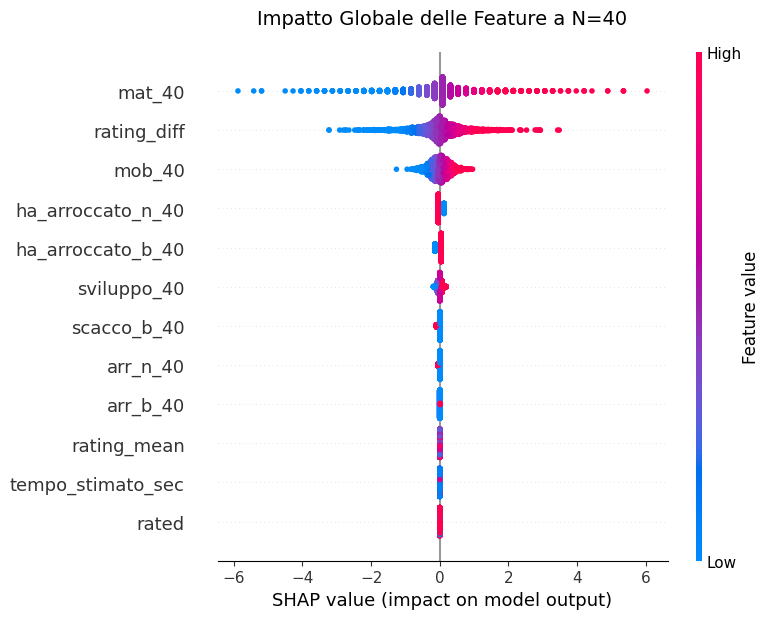

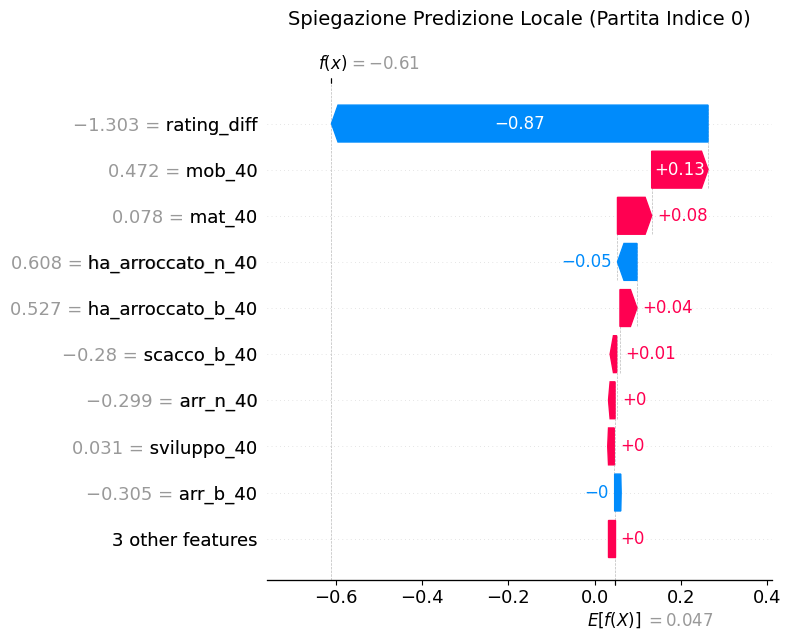

In [2]:
import shap
import matplotlib.pyplot as plt

print("--- GENERAZIONE GRAFICI SHAP (N=40) ---")

# Inizializza il masker usando l'intero Train Set scalato (elimina il warning del subsampling)
masker = shap.maskers.Independent(X_train_40_scaled_df, max_samples=len(X_train_40_scaled_df))

# Inizializza l'Explainer sul modello lineare puro estratto dalla Pipeline
explainer = shap.LinearExplainer(modello_40_logreg, masker=masker)
shap_values = explainer(X_test_40_scaled_df)

# Grafico 1: L'Importanza Globale (Summary Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_40_scaled_df, show=False)
plt.title("Impatto Globale delle Feature a N=40", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# Grafico 2: La spiegazione di una partita locale (Waterfall Plot)
indice_partita = 0
base_value = explainer.expected_value

plt.figure(figsize=(8, 5))
shap.waterfall_plot(shap.Explanation(values=shap_values.values[indice_partita],
                                     base_values=base_value,
                                     data=X_test_40_scaled_df.iloc[indice_partita],
                                     feature_names=X_test_40_scaled_df.columns), show=False)
plt.title(f"Spiegazione Predizione Locale (Partita Indice {indice_partita})", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### Interpretabilità del Modello a N=40 (Analisi SHAP)

L'analisi SHAP condotta sul modello ottimizzato a $N=40$ (`C=0.032`, penalità L1) con l'intero Training Set come background conferma la piena coerenza scacchistica delle decisioni apprese (i contributi sono espressi in *log-odds* rispetto alla vittoria del Bianco):

* **Importanza Globale (Summary Plot):** Alla 40ª semimossa il vantaggio materiale (`mat_40`) emerge come il fattore più influente in assoluto, superando persino il divario di rating (`rating_diff`), seguito dalla mobilità (`mob_40`). Tutte le feature principali presentano una relazione monotona e coerente: valori più alti a favore del Bianco spingono positivamente la predizione. Seguono, con contributo minore ma segno corretto, gli indicatori di arrocco (`ha_arroccato_n_40` con effetto negativo e `ha_arroccato_b_40` con effetto positivo) e lo sviluppo (`sviluppo_40`).
* **Effetto della regolarizzazione L1 e assenza di collinearità:** Le variabili prive di capacità discriminativa diretta sull'esito Bianco/Nero, in particolare `rating_mean`, `tempo_stimato_sec` e `rated` risultano azzerate dalla penalità L1. L'annullamento di rating_mean conferma inoltre che la riparametrizzazione ortogonale ha isolato l'intero effetto della forza dei giocatori su `rating_diff`.
* **Spiegazione Locale (Waterfall Plot — Partita Indice 0):** Il valore atteso di base $E[f(X)] = 0.047$ ($\approx 51.2\%$ di probabilità per il Bianco) riflette il leggero vantaggio statistico della prima mossa. Nel caso della prima partita del Test Set (dove i valori grigi a sinistra indicano le feature standardizzate in *z-score*), il Bianco beneficia di un leggero vantaggio posizionale in mobilità (`+0.13`) e materiale (`+0.08`), mentre gli arrocchi di entrambi i giocatori quasi si compensano (`+0.04` vs `-0.05`). Tuttavia, il marcato svantaggio di Elo (`rating_diff = -1.303`, impatto `-0.87`) domina la valutazione complessiva, portando l'output finale a $f(x) = -0.61$ ($\approx 35.2\%$ di probabilità per il Bianco, ovvero $\approx 64.8\%$ per il Nero).